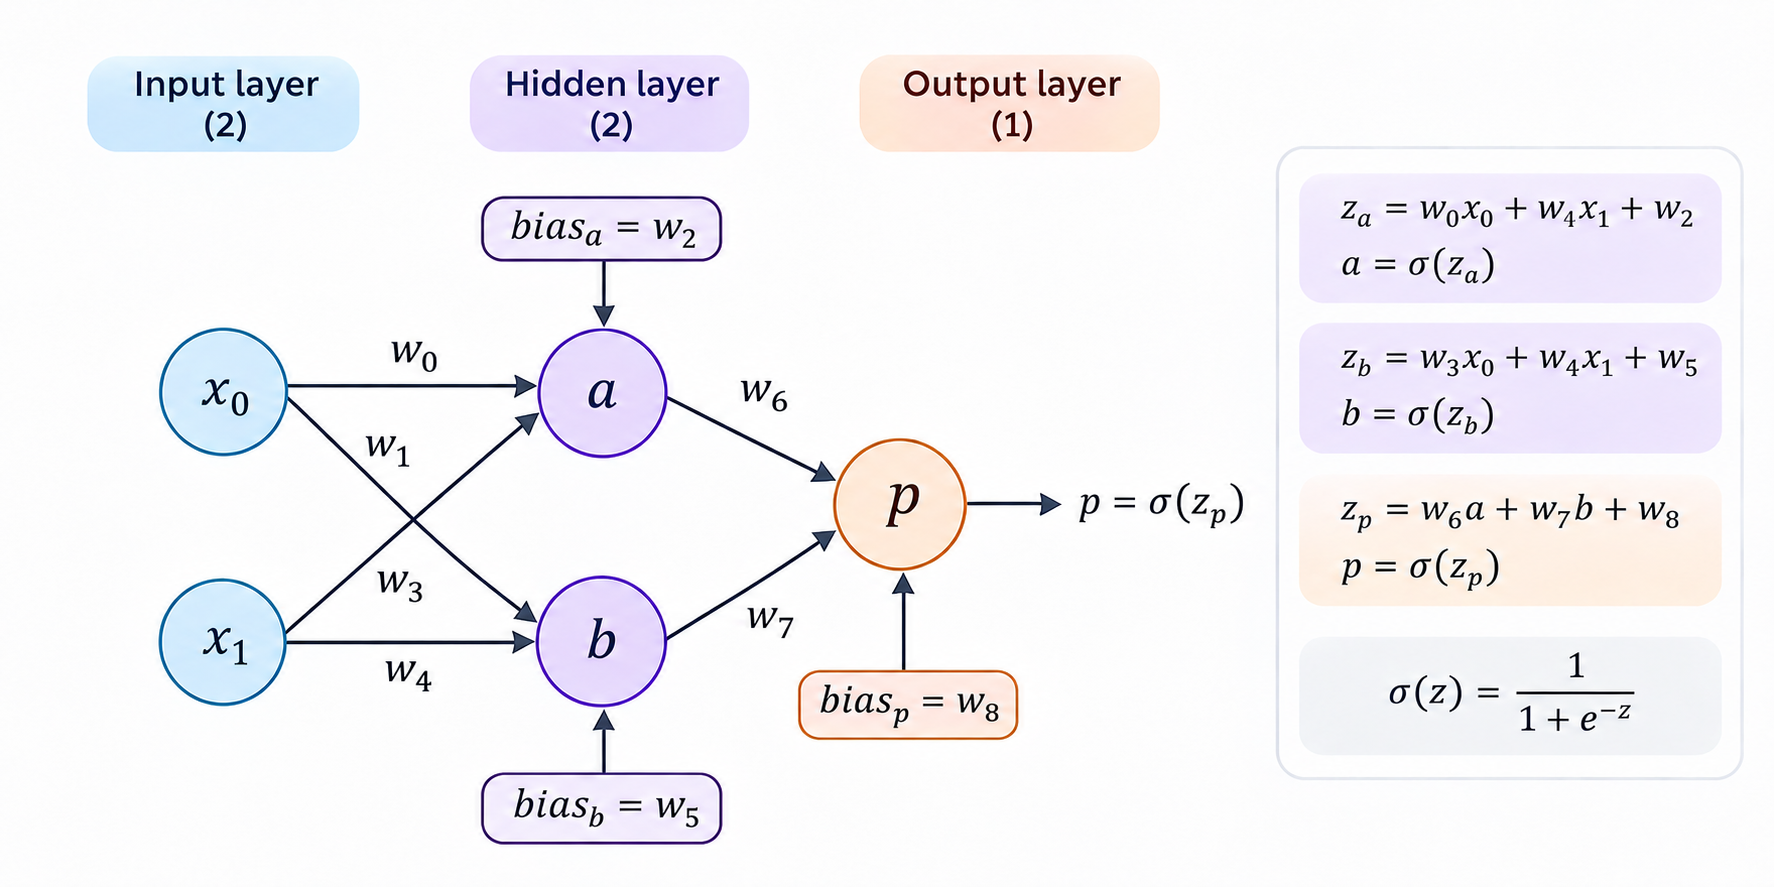

In [8]:
import math

# XOR training data: (x0, x1, target)
data = [(0, 0, 0), (0, 1, 1),
        (1, 0, 1), (1, 1, 0)]

# Sigmoid activation
sig = lambda z: 1 / (1 + math.exp(-z))

# 2 hidden neurons + 1 output neuron (9 parameters)
# [w0,w1,b_a, w3,w4,b_b, w6,w7,b_p]
w = [.3, -.8, .5, -.2, .9, .1, .7, -.6, .2]
lr = 0.5

<div align="center">
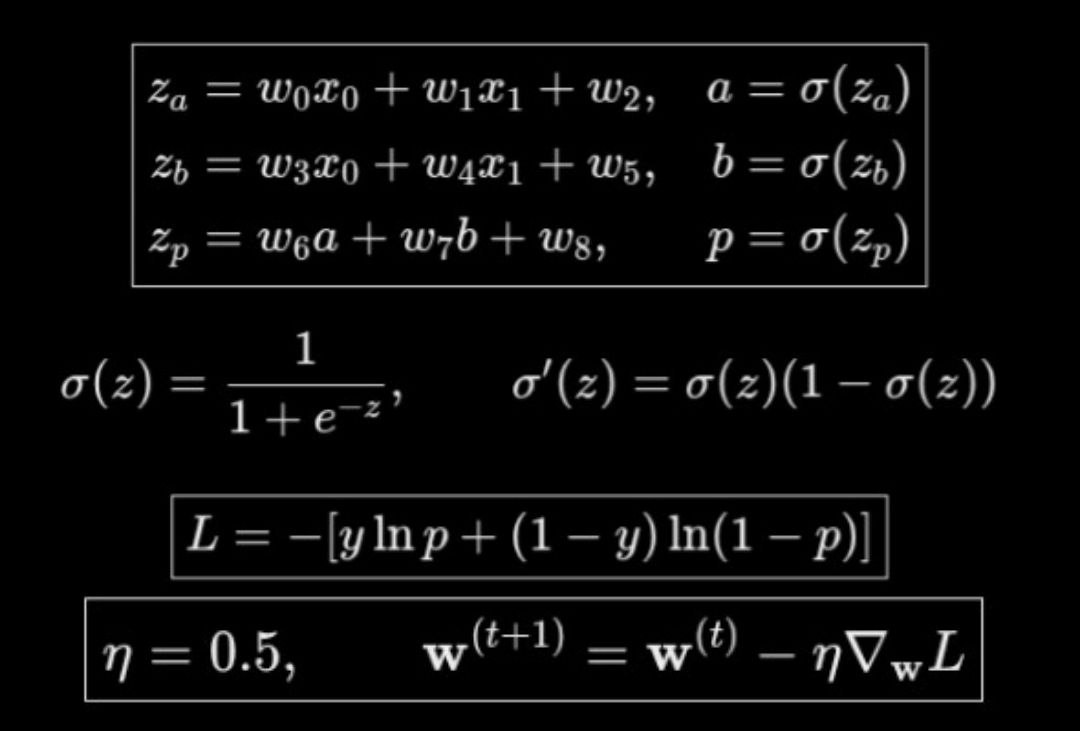
</div>

<div style="display: flex; justify-content: center; align-items: flex-start; gap: 2%; flex-wrap: nowrap; width: 100%; margin-left: 0;">
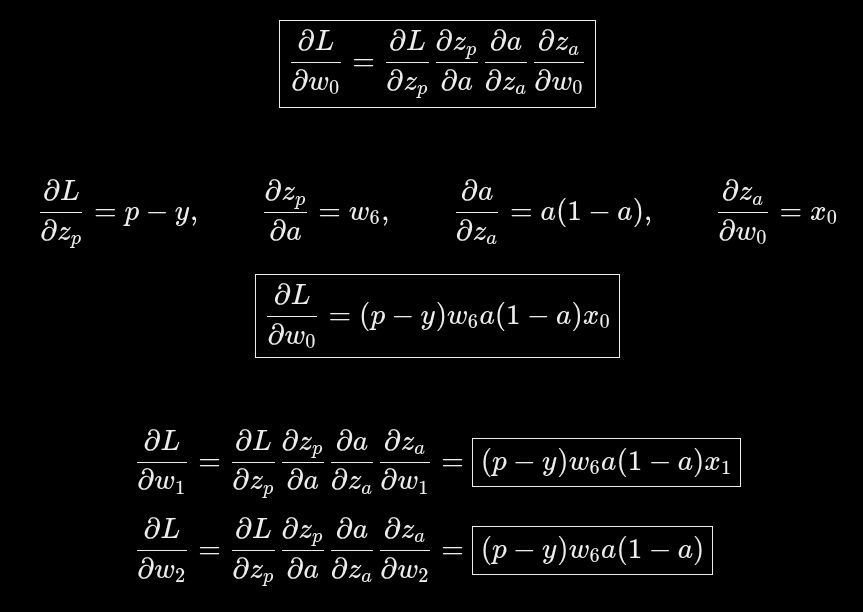
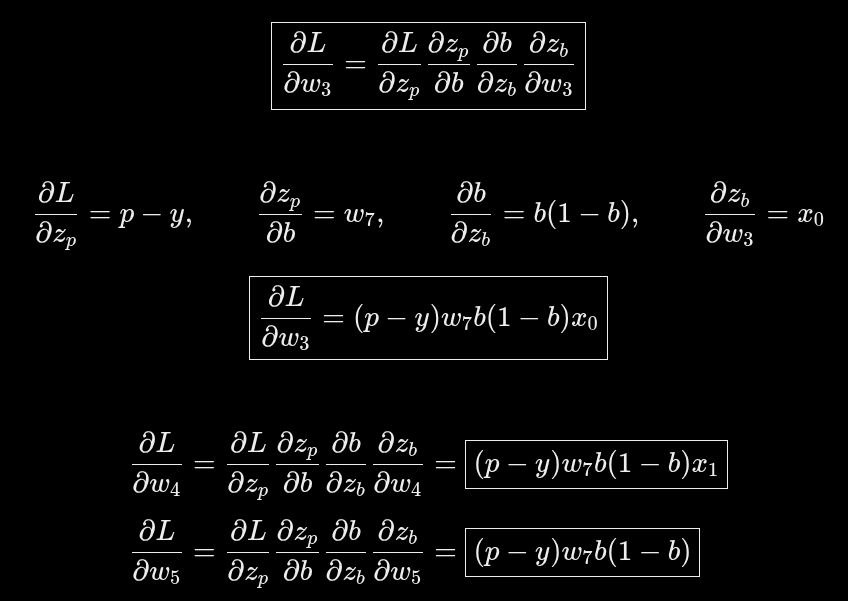
</div>
<div style="text-align: center; margin-top: 12px;">
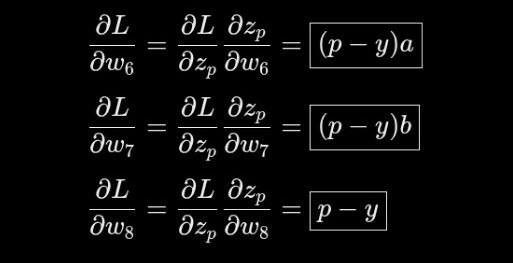
</div>

<div align="center">
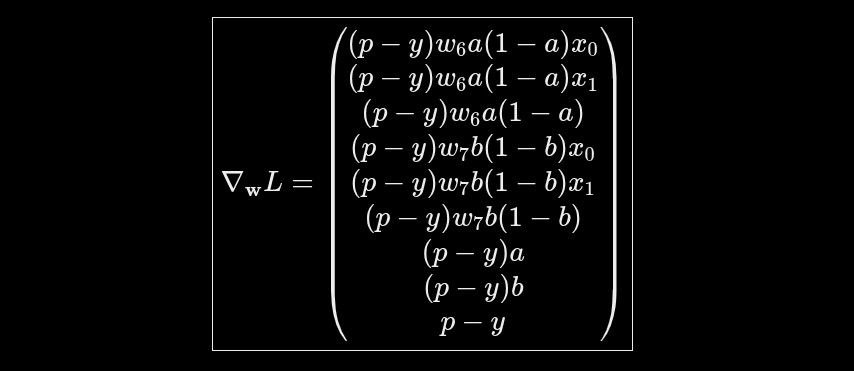
</div>

In [9]:
for epoch in range(3000):
    # SGD: update parameters after EACH sample
    for x0, x1, y in data:

        # Forward pass: hidden layer
        a = sig(w[0]*x0 + w[1]*x1 + w[2])
        b = sig(w[3]*x0 + w[4]*x1 + w[5])

        # Forward pass: output neuron
        p = sig(w[6]*a + w[7]*b + w[8])

        # Output gradient (BCE + sigmoid): dL/dz_p
        err = p - y

        # Backpropagation: hidden layer gradients
        ga = err * w[6] * a * (1 - a)  # dL/dz_a
        gb = err * w[7] * b * (1 - b)  # dL/dz_b

        # Partial derivatives for all 9 parameters
        grad = [ga*x0, ga*x1, ga,
                gb*x0, gb*x1, gb,
                err*a, err*b, err]

        # SGD: immediate parameter update
        for i in range(9):
            w[i] -= lr * grad[i]

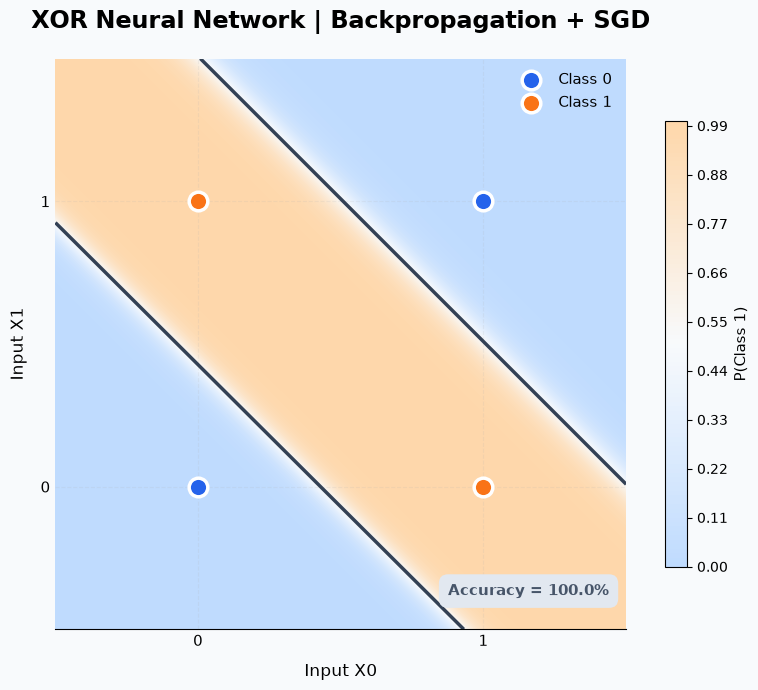

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Convert training data to arrays
X = np.array([(x0, x1) for x0, x1, y in data])
y = np.array([target for x0, x1, target in data])

# Vectorized sigmoid and forward pass
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def predict(x0, x1):
    a = sigmoid(w[0]*x0 + w[1]*x1 + w[2])
    b = sigmoid(w[3]*x0 + w[4]*x1 + w[5])
    return sigmoid(w[6]*a + w[7]*b + w[8])

# Create a 2D grid of input coordinates
axis = np.linspace(-0.5, 1.5, 400)
xx, yy = np.meshgrid(axis, axis)

# Compute predicted probabilities across the grid
zz = predict(xx, yy)

# Modern visualization
fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor("#f8fafc")
ax.set_facecolor("#f8fafc")

# Soft probability background: blue -> white -> orange
cmap = LinearSegmentedColormap.from_list(
    "xor", ["#bfdbfe", "#f8fafc", "#fed7aa"]
)

heatmap = ax.contourf(
    xx, yy, zz,
    levels=np.linspace(0, 1, 101),
    cmap=cmap, vmin=0, vmax=1
)

# Decision boundary: P(class 1) = 0.5
if zz.min() <= 0.5 <= zz.max():
    ax.contour(xx, yy, zz, levels=[0.5],
               colors=["#334155"], linewidths=2.5)

# Training samples
for label, color, name in [
    (0, "#2563eb", "Class 0"),
    (1, "#f97316", "Class 1")
]:
    points = X[y == label]
    ax.scatter(points[:, 0], points[:, 1],
               s=180, color=color, edgecolors="white",
               linewidths=2.5, zorder=5, label=name)

# Evaluate training accuracy
probs = predict(X[:, 0], X[:, 1])
predictions = (probs >= 0.5).astype(int)
accuracy = np.mean(predictions == y)

# Labels and styling
ax.set_title("XOR Neural Network | Backpropagation + SGD",
             fontsize=17, fontweight="bold", pad=22)
ax.set_xlabel("Input X0", fontsize=12, labelpad=10)
ax.set_ylabel("Input X1", fontsize=12, labelpad=10)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.15)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(length=0, labelsize=11)
ax.legend(frameon=False, fontsize=11, loc="upper right")

# Model performance
ax.text(0.97, 0.06, f"Accuracy = {accuracy:.1%}",
        transform=ax.transAxes, ha="right",
        fontsize=11, fontweight="bold", color="#475569",
        bbox=dict(boxstyle="round,pad=0.6",
                  facecolor="#e2e8f0", edgecolor="none"))

# Probability colorbar
cbar = fig.colorbar(heatmap, ax=ax, shrink=0.78, pad=0.04)
cbar.set_label("P(Class 1)", fontsize=11)

plt.tight_layout()
plt.show()
